In [ ]:
print("Welcome to business Analytics")


Welcome to business Analytics


In [ ]:
price= 500
quantity=10
sales=price* quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

good sales


In [ ]:
#Number type
#1. integer
age=25
print(age)
print(type(age))

25
<class 'int'>


2.float

In [ ]:
price=99.50
print(price)
print(type(price))

99.5
<class 'float'>


3.complex

In [ ]:
z=3+4j
print(z)
print(type(z))

(3+4j)
<class 'complex'>


In [ ]:
price= 500
quantity=10
sales=price + quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

low sales


In [ ]:
price= 500
quantity=10
sales=price- quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

low sales


In [ ]:
price= 500
quantity=10
sales=price/ quantity
if sales> 4000:
  print("good sales")
else:
    print("low sales")

low sales


In [ ]:
#small business: chai stall
units_sold= 500
price_per_unit= 15
cost_per_unit=9
rent= 2000
target_profit= 2500
#arithmetic operators
revenue= price_per_unit*units_sold
cost=cost_per_unit*units_sold
profit=revenue - cost
margin=(profit/revenue)*100
print("Revenue:", revenue)
print("Cost:", cost)
print("Profit:", profit)
print(f"Margin: {margin:.2f}%")
# Comparison operators
print("Profit > target?", profit > target_profit)
print("Profit >= target?", profit >= target_profit)
print("Revenue < cost?", revenue < cost)
print("Price == cost?", price_per_unit == cost_per_unit)
print("Price != cost?", price_per_unit != cost_per_unit)

# Using comparison in a decision
if profit >= target_profit:
    print("Target achieved ")
else:
    print("Below target, reduce costs or raise price")


Revenue: 7500
Cost: 4500
Profit: 3000
Margin: 40.00%
Profit > target? True
Profit >= target? True
Revenue < cost? False
Price == cost? False
Price != cost? True
Target achieved 


!pip install seaborn plotly openpyxl           only if a library is missing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Loaded using the correct sheet name 'Orders_Data'
df=pd.read_excel("Zomato_India_Orders_Dataset.xlsx", sheet_name="Orders_Data")
print("data loaded:",df.shape[0],"orders and",df.shape[1],"variables")

FileNotFoundError: [Errno 2] No such file or directory: 'Zomato_India_Orders_Dataset.xlsx'

about the dataset

1.shape: tells us the number of rows and columns

In [ ]:
print("shape:",df.shape)

2. columns: shows the names of all column

In [ ]:
print("\ncoloumn:")
print(df.columns)

3. index:shows the row labels

In [ ]:
print("\nindex:")
print(df.index)

4.data types: tells us the type of data in each column


In [ ]:
print("\ndata types:")
print(df.dtypes)

classification of variables

In [ ]:
#1.5 classify the variables(we decide this using the data dictionary)
number_cols  = ["items_count","order_values","discount_pct","delivery_fee","distance_km","delivery_time_min","rating","final_amount"]
category_cols = ["city","cuisine","customer_segment","platform","payment_mode"]
date_cols = ["order_data"]
id_cols = ["order_id"]
print("number cols:",len(number_cols), number_cols)
print("category cols:",len(category_cols),category_cols)
print("date cols:",date_cols)
print("id cols:",id_cols)


finding missing values

#summarystatistics/ discriptive statistics

In [ ]:
df.describe()

#descriptive statistics for specific classification

In [ ]:
#2.1 describe(): one command, many statistics(numerical columns)
# Corrected the column names to match the exact capitalization in df
number_cols = ["Items_Count", "Order_Value", "Discount_Pct", "Delivery_Fee", "Distance_Km", "Delivery_Time_Min", "Rating", "Final_Amount"]
df[number_cols].describe().round(2)

#statistics for single variable

In [ ]:
#2.2 statistics for one important column:Final_amount(what the customer)
amount=df["Final_Amount"]

print("mean(average):rs",round(amount.mean(),2))
print("median(middle value):rs",amount.median(),)
print("mode(most common):rs",amount.mode()[0])
print("min:rs ",amount.min())
print("max:rs",amount.max())
print("standard deviation:rs",round(amount.std(),2))
print("range(max-min):rs",amount.max()-amount.min())

LECTURE 7
DATA CLEARNING AND DATA  MANIPULATION
CASE OF AIRLINE


In [ ]:
#METHOD 1
import pandas as pd
file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
df=pd.read_excel(file_path,sheet_name="Unclean_Data")
df.head()

In [ ]:
#method 2
raw= pd.read_excel("SkyBridge_Airline_Data (1).xlsx",sheet_name="Unclean_Data")
# the 9 numeric column we will study
num_cols = ["passengers","ticket_price", "delay_minutes","flight_duration_min", "fuel_cost","ancillary_revenue","baggage_complaints","customer_rating","crew_overtime_hours"]

print("rows and column", raw.shape)
raw.head()

In [ ]:
import pandas as pd

# Safely load 'raw' if it is not currently in memory, then display the dataset info
try:
    raw.info()
except NameError:
    print("'raw' was not in memory. Loading the dataset now...")
    raw = pd.read_excel("SkyBridge_Airline_Data (1).xlsx", sheet_name="Unclean_Data")
    raw.info()

'raw' was not in memory. Loading the dataset now...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 120 non-null    datetime64[ns]
 1   Flight_ID            120 non-null    object        
 2   Route                116 non-null    object        
 3   Passengers           115 non-null    float64       
 4   Ticket_Price         113 non-null    float64       
 5   Delay_Minutes        114 non-null    float64       
 6   Flight_Duration_Min  116 non-null    float64       
 7   Fuel_Cost            114 non-null    float64       
 8   Ancillary_Revenue    114 non-null    float64       
 9   Baggage_Complaints   115 non-null    float64       
 10  Customer_Rating      113 non-null    float64       
 11  Crew_Overtime_Hours  112 non-null    float64       
dtypes: datetime64[ns](1), float64(9), object

step 2 lecture topic: unsual values in business datasets

In [ ]:
total_blank =raw.isnull().sum().sum()
print("total blank:",total_blank)
print("blank % :", round(total_blank/raw.size* 100,1),"%")
print("rows with at least one blank:",raw.isnull().any(axis=1).sum(),"out of",len(raw))


BEFORE heatmap:red= blank cell,grey=filled cell

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Corrected '#d627728' (7 characters) to '#d62728' (6 characters)
colors = ListedColormap(["#d9d9d9", "#d62728"])
plt.figure(figsize=(10, 6))

sns.heatmap(raw.isnull(), cmap=colors, cbar=False, yticklabels=False)

plt.title("BEFORE cleaning: blank cells in raw data (red blank)")

plt.show()

STEP3 lecture topic: unsual values in businesss datasets
discriptive statistics: spot values that look wrong

In [ ]:
raw[num_cols_clean].describe().round(1)

In [ ]:
# A big gap between mean and median is a warning sign

# Corrected 'num_cols' to 'num_cols_clean' to match capitalized columns
gap = pd.DataFrame({
    "Mean": raw[num_cols_clean].mean(),
    "Median": raw[num_cols_clean].median(),
})

gap["Gap %"] = (
    (gap["Mean"] - gap["Median"]) / gap["Median" ] * 100
).round(1)

gap.round(1)

,Mean,Median,Gap %
Passengers,155.0,155.0,-0.0
Ticket_Price,6374.3,5900.0,8.0
Delay_Minutes,19.4,16.0,21.2
Flight_Duration_Min,157.2,165.0,-4.7
Fuel_Cost,511.2,530.0,-3.5
Ancillary_Revenue,59615.8,58800.0,1.4
Baggage_Complaints,3.1,3.0,3.5
Customer_Rating,4.2,4.1,1.8
Crew_Overtime_Hours,6.5,6.1,6.2


step1 for missing value-settingup rule for each variables

In [ ]:
rules = {
    "Passengers": (0, 180),
    "Ticket_Price": (1000, 20000),
    "Delay_Minutes": (0, 600),  # Changed from 'Delay Minutes' to match column name, and low from 8 to 0 since delays can be 0
    "Flight_Duration_Min": (60, 240),
    "Customer_Rating": (1, 5),
}

# aircraft has 180 seats
# domestic low-cost fare in INR
# a delay cannot be negative
# domestic sector
# rating scale 1 to 5

for col, (low, high) in rules.items():
    # Filtering the rows where the column values fall outside the rules
    bad = raw[(raw[col] < low) | (raw[col] > high)]

    print(col, "-> impossible values:", len(bad))
    if len(bad) > 0:
        print(bad[["Date", "Flight_ID", col]].to_string(index=False))
    print()

Passengers -> impossible values: 1
      Date Flight_ID  Passengers
2026-02-07    SB-038       215.0

Ticket_Price -> impossible values: 1
      Date Flight_ID  Ticket_Price
2026-01-15    SB-015       57000.0

Delay_Minutes -> impossible values: 1
      Date Flight_ID  Delay_Minutes
2026-01-23    SB-023          -45.0

Flight_Duration_Min -> impossible values: 1
      Date Flight_ID  Flight_Duration_Min
2026-04-02    SB-092                410.0

Customer_Rating -> impossible values: 1
      Date Flight_ID  Customer_Rating
2026-03-18    SB-077              9.4



step-2 Time series view (one flight per day)

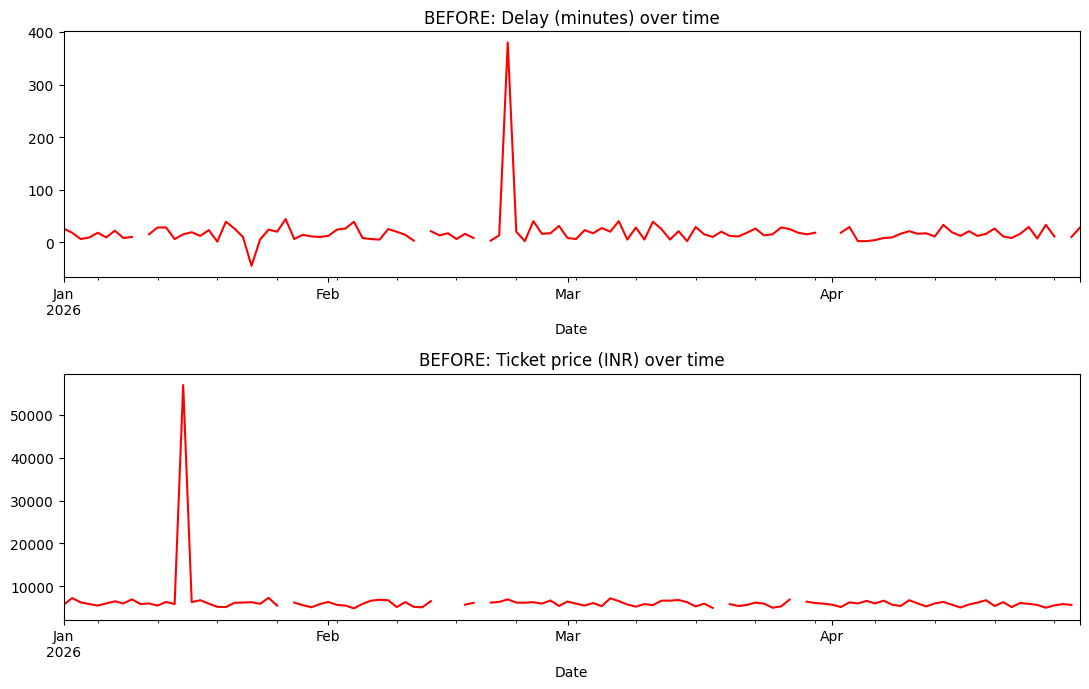

In [ ]:
ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

# Corrected 'ax-axes[0]' to 'ax=axes[0]'
ts_raw["Delay_Minutes"].plot(ax=axes[0], color="red", title="BEFORE: Delay (minutes) over time")

ts_raw["Ticket_Price"].plot(ax=axes[1], color="red", title="BEFORE: Ticket price (INR) over time")

plt.tight_layout()

plt.show()

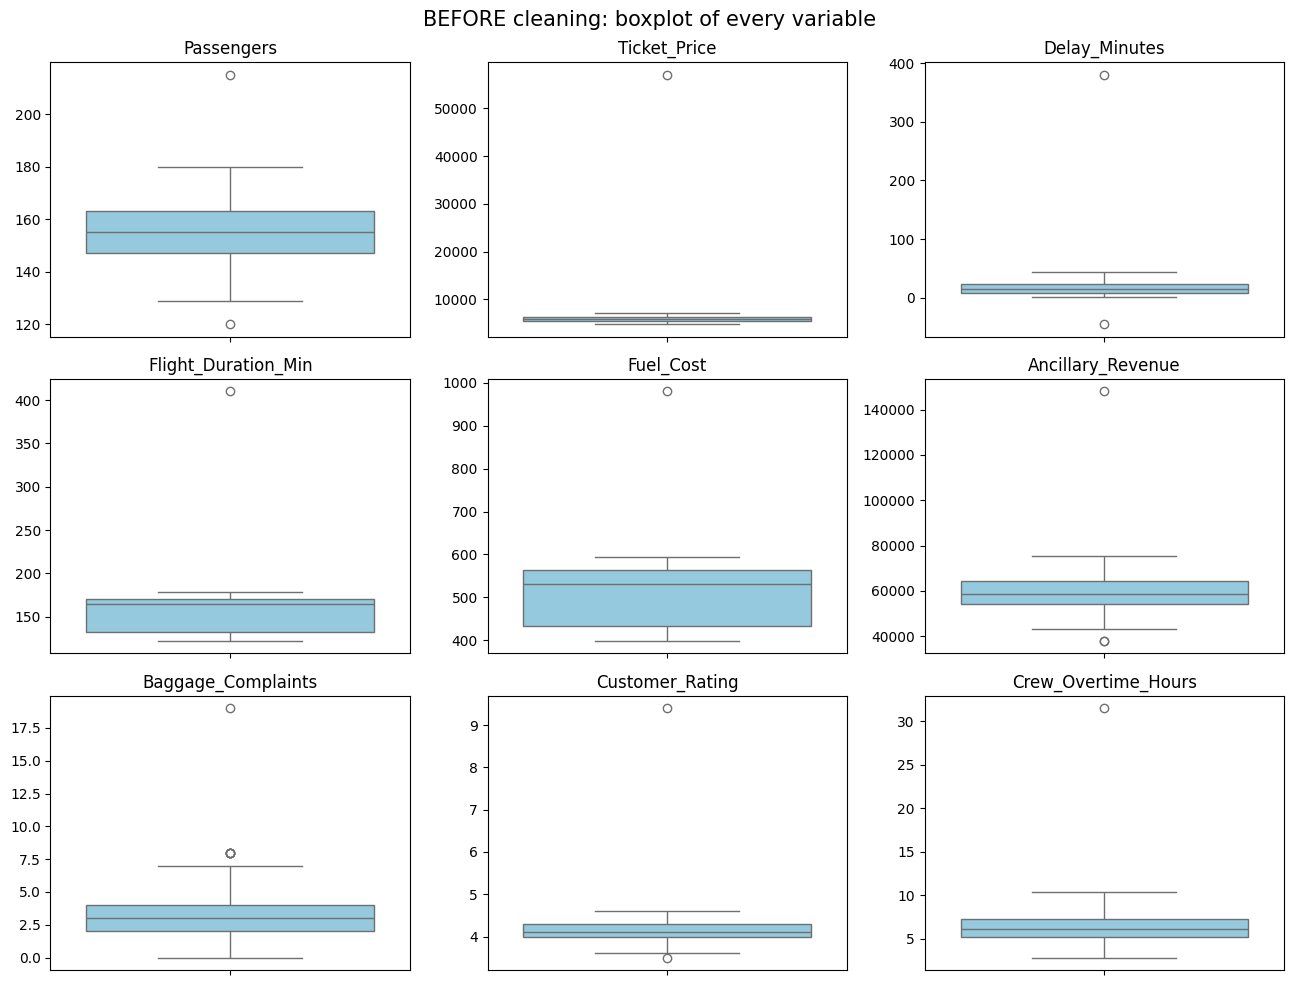

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define the list of cleaned, capitalized numeric columns
num_cols_clean = [
    "Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration_Min",
    "Fuel_Cost", "Ancillary_Revenue", "Baggage_Complaints",
    "Customer_Rating", "Crew_Overtime_Hours"
]

def show_boxplots(data, title):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    axes = axes.flatten()
    for i, col in enumerate(num_cols_clean):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")

Step-3 retaining removing and capping the data

In [ ]:
raw[raw["Delay_Minutes"] > 100]

Step-4 removing impossible values

In [ ]:
#create a copy
df = raw.copy()
# Find rating below 1 or above 5
bad_values = (df["Customer_Rating"] < 1) | (df["Customer_Rating"] > 5)

# Count unusual ratings
print("Unusual ratings:", bad_values.sum())

# Replace unusual ratings with missing values
df.loc[bad_values, "Customer_Rating"] = np.nan

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())

print("Missing cells after:", df.isnull().sum().sum())

Unusual ratings: 1
Missing cells before: 58
Missing cells after: 59


Step-5 Capping

Maximum before: 148000.0
Maximum after: 78925.0
Upper limit: 78925.0


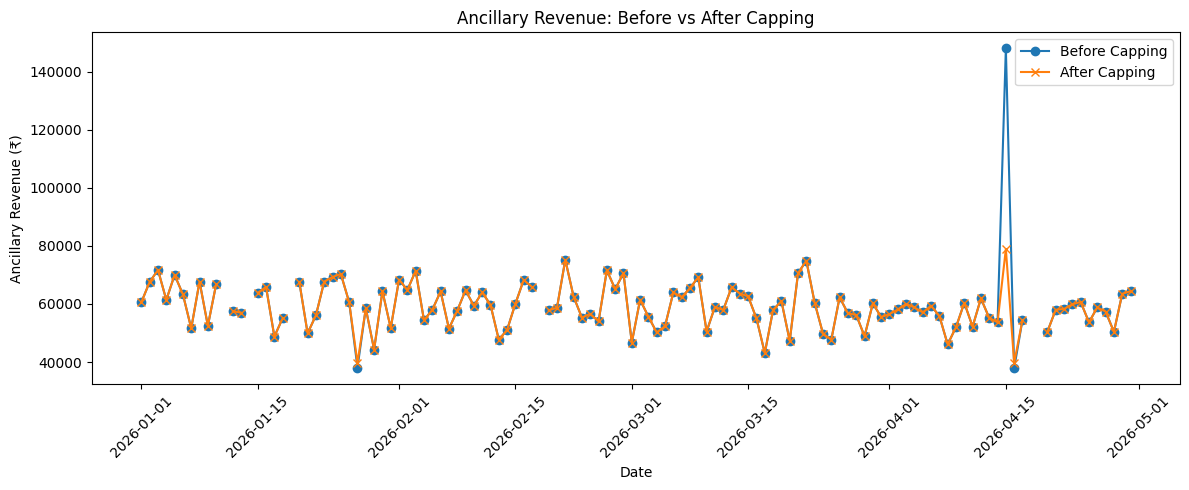

In [ ]:
# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))

plt.plot(raw["Date"], before,
         label="Before Capping", marker="o")

plt.plot(raw["Date"], df_capped[col],
         label="After Capping", marker="x")

plt.title("Ancillary Revenue: Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Ancillary Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

LECTURE-8 RETAIN: flagged by 1QR but posiible. we leave these values uncharged

In [ ]:
# Example we keep: flights with delay > 100, passengers < 125, or baggage complaints >= 8
conditions = (
    (df["Delay_Minutes"] > 100) |
    (df["Passengers"] < 125) |
    (df["Baggage_Complaints"] >= 8)
)

df[conditions][["Date", "Passengers", "Delay_Minutes", "Baggage_Complaints"]]

,Date,Passengers,Delay_Minutes,Baggage_Complaints
26,2026-01-27,120.0,44.0,2.0
33,2026-02-03,169.0,26.0,8.0
52,2026-02-22,147.0,380.0,19.0
63,2026-03-05,167.0,27.0,8.0
76,2026-03-18,157.0,10.0,8.0
104,2026-04-15,143.0,19.0,8.0
109,2026-04-20,143.0,26.0,8.0


Drop the values

In [ ]:
#method 1: remove rows consisting missing values
df_drop = df.dropna()

# Show descriptive statistics before removing missing values
print("DESCRIPTIVE STATISTICS BEFORE dropna()")
display(df.describe().round(2))

# Show descriptive statistics after removing missing values
print("DESCRIPTIVE STATISTICS AFTER dropna()")
display(df_drop.describe().round(2))

# Compare the number of rows
print("Rows before:", len(df))
print("Rows after :", len(df_drop))

# Calculate percentage of data lost
print("Data lost:", round((1 - len(df_drop) / len(df)) * 100, 1), "%")
#check missing values in each column after dropna()
print("missing_values after dropna():")
print(df_drop.isnull().sum())

# Count all missing cells in the dataset
print("Total blank cells:", df_drop.isnull().sum().sum())

DESCRIPTIVE STATISTICS BEFORE dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,112.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.26,2.81


DESCRIPTIVE STATISTICS AFTER dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,71,71.00,71.00,71.00,71.00,71.00,71.00,71.00,71.00,71.00
mean,2026-02-27 22:18:35.492957696,155.49,5965.49,22.42,154.34,513.34,60826.76,3.15,4.13,6.74
min,2026-01-02 00:00:00,129.00,4800.00,2.00,122.00,398.00,44300.00,0.00,3.60,3.90
25%,2026-01-31 12:00:00,148.50,5550.00,10.00,132.00,433.00,55150.00,2.00,4.00,5.15
50%,2026-02-27 00:00:00,155.00,5950.00,17.00,165.00,530.00,59400.00,3.00,4.10,6.30
75%,2026-03-28 00:00:00,161.50,6300.00,24.50,169.00,563.50,64350.00,4.00,4.30,7.50
max,2026-04-29 00:00:00,180.00,7250.00,380.00,179.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,11.46,574.99,44.10,18.82,85.26,12653.82,2.74,0.23,3.35


Rows before: 120
Rows after : 71
Data lost: 40.8 %
missing_values after dropna():
Date                   0
Flight_ID              0
Route                  0
Passengers             0
Ticket_Price           0
Delay_Minutes          0
Flight_Duration_Min    0
Fuel_Cost              0
Ancillary_Revenue      0
Baggage_Complaints     0
Customer_Rating        0
Crew_Overtime_Hours    0
dtype: int64
Total blank cells: 0


METHOD-*2* Substituting of mean

In [ ]:
#create a copy of the original dataset
df_mean = df.copy()

# Display descriptive statistics BEFORE filling missing values
print("DESCRIPTIVE STATISTICS BEFORE IMPUTATION")
display(df.describe().round(2))

# Use the defined list of cleaned, capitalized numeric columns
# Fill missing values in numeric columns using the mean
df_mean[num_cols_clean] = df_mean[num_cols_clean].fillna(df_mean[num_cols_clean].mean())

# Fill missing Route values using the most common route (mode)
df_mean["Route"] = df_mean["Route"].fillna(df_mean["Route"].mode()[0])

# Display descriptive statistics AFTER filling missing values
print("DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION")
display(df_mean.describe().round(2))

# Compare the number of rows before and after
print("Rows before:", len(df))
print("Rows after:", len(df_mean))

#count missing cells remaining after imputation
print("blanks left:", df_mean.isnull().sum().sum())

DESCRIPTIVE STATISTICS BEFORE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,112.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.26,2.81


DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5587.50,9.75,132.75,433.75,54875.00,2.00,4.00,5.28
50%,2026-03-01 12:00:00,154.96,5950.00,16.00,165.00,529.50,59400.00,3.00,4.13,6.30
75%,2026-03-31 06:00:00,162.25,6356.08,23.00,169.25,563.00,64000.00,4.00,4.30,7.22
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.32,4692.30,34.97,29.50,76.04,10896.78,2.36,0.25,2.71


Rows before: 120
Rows after: 120
blanks left: 0


inputation with mode

In [ ]:
df_mode = df.copy()
for col in df_mode.columns:
     df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])
print("blank left:", df_mode.isnull().sum().sum())

blank left: 0


In [ ]:
# Descriptive Statistics

# Display descriptive statistics for the dataset
print("DESCRIPTIVE STATISTICS")

display(df.describe().round(2))

# Check data types and non-null values
print("DATASET INFORMATION")
df.info()

# Check missing values in each column
print("MISSING VALUES")
print(df.isnull().sum())

# Calculate mean, median, and mode
print("MEAN")
display(df.mean(numeric_only=True).round(2))

print("MEDIAN")
display(df.median(numeric_only=True).round(2))

print("MODE")
display(df.mode().head(1))

DESCRIPTIVE STATISTICS


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,112.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.26,2.81


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 120 non-null    datetime64[ns]
 1   Flight_ID            120 non-null    object        
 2   Route                116 non-null    object        
 3   Passengers           115 non-null    float64       
 4   Ticket_Price         113 non-null    float64       
 5   Delay_Minutes        114 non-null    float64       
 6   Flight_Duration_Min  116 non-null    float64       
 7   Fuel_Cost            114 non-null    float64       
 8   Ancillary_Revenue    114 non-null    float64       
 9   Baggage_Complaints   115 non-null    float64       
 10  Customer_Rating      112 non-null    float64       
 11  Crew_Overtime_Hours  112 non-null    float64       
dtypes: datetime64[ns](1), float64(9), object(2)
memory usage: 11.4+ KB
MISSI

,0
Passengers,154.96
Ticket_Price,6374.34
Delay_Minutes,19.39
Flight_Duration_Min,157.19
Fuel_Cost,511.22
Ancillary_Revenue,59615.79
Baggage_Complaints,3.10
Customer_Rating,4.13
Crew_Overtime_Hours,6.48


MEDIAN


,0
Passengers,155.0
Ticket_Price,5900.0
Delay_Minutes,16.0
Flight_Duration_Min,165.0
Fuel_Cost,530.0
Ancillary_Revenue,58800.0
Baggage_Complaints,3.0
Customer_Rating,4.1
Crew_Overtime_Hours,6.1


MODE


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Bengaluru,159.0,5800.0,6.0,129.0,530.0,58000.0,2.0,4.1,4.8


METHOD-4 MEDIAN INPUTATION

In [ ]:
df_median = df.copy()
df_median[num_cols_clean] = df_median[num_cols_clean].fillna(
    df_median[num_cols_clean].median()
)

# Route is text, so use the most common route
df_median["Route"] = df_median["Route"].fillna(
    df_median["Route"].mode()[0]
)

# Check remaining missing values
print("Blanks left:", df_median.isnull().sum().sum())

Blanks left: 0


HEATPLOTS after treatment

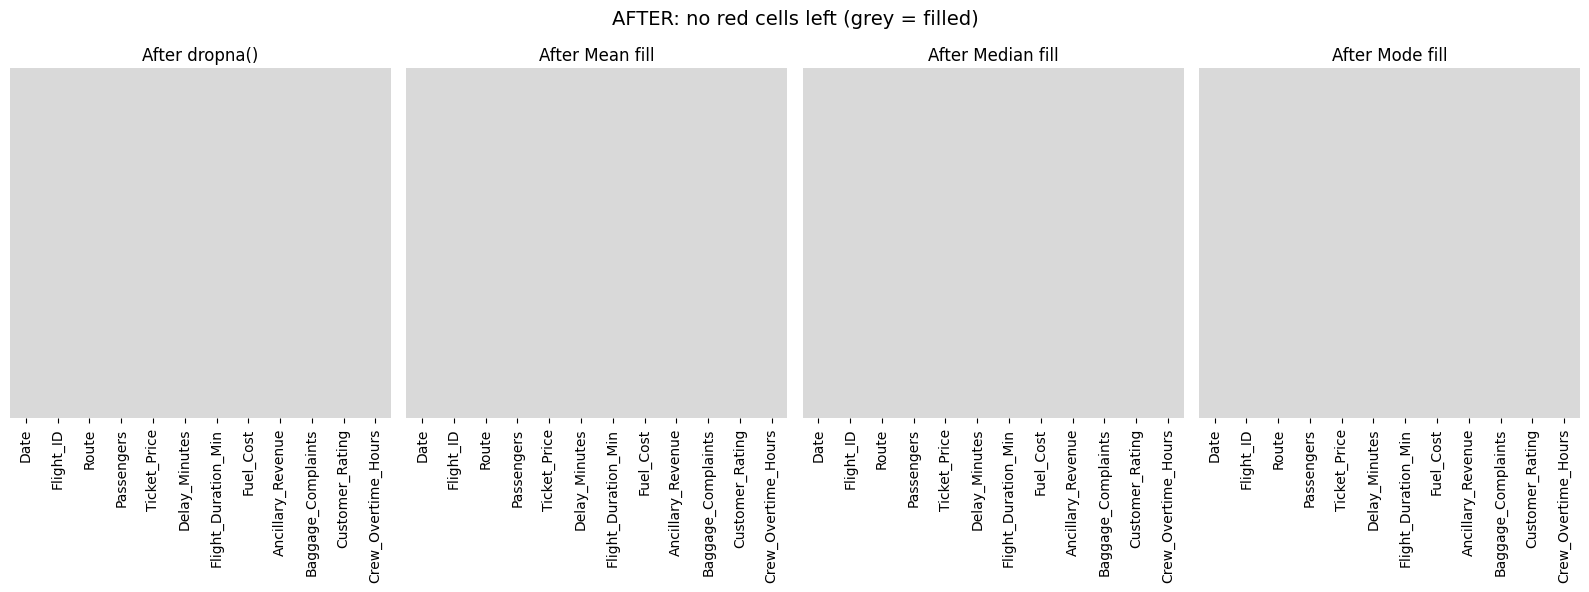

In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import seaborn as sns

# Redefining the colors variable to resolve the NameError
colors = ListedColormap(["#d9d9d9", "#d62728"])

fig, axes = plt.subplots(1, 4, figsize=(16, 6))

sns.heatmap(df_drop.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("After dropna()")

sns.heatmap(df_mean.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("After Mean fill")

sns.heatmap(df_median.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[2])
axes[2].set_title("After Median fill")

sns.heatmap(df_mode.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[3])
axes[3].set_title("After Mode fill")

plt.suptitle("AFTER: no red cells left (grey = filled)", fontsize=14)
plt.tight_layout()
plt.show()

BOXPLOT AFTER INPUTATION

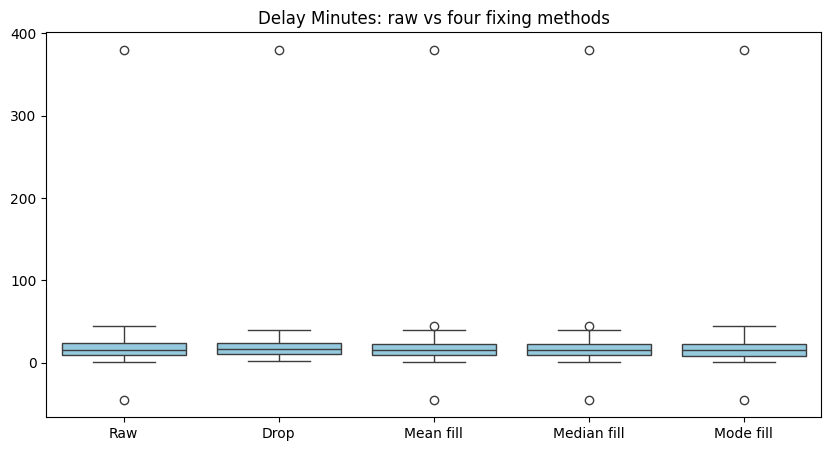

52     380.0
26      44.0
65      40.0
55      40.0
19      39.0
34      39.0
69      39.0
115     33.0
103     33.0
58      31.0
Name: Delay_Minutes, dtype: float64


In [ ]:
# Boxplot of Delay_Minutes: raw versus the four methods

delay_compare = pd.DataFrame({
    "Raw": raw["Delay_Minutes"],
    "Drop": df_drop["Delay_Minutes"],
    "Mean fill": df_mean["Delay_Minutes"],
    "Median fill": df_median["Delay_Minutes"],
    "Mode fill": df_mode["Delay_Minutes"]
})

plt.figure(figsize=(10, 5))
sns.boxplot(data=delay_compare, color="skyblue")
plt.title("Delay Minutes: raw vs four fixing methods")
plt.show()

# Check the largest delay values
print(
    raw["Delay_Minutes"]
    .sort_values(ascending=False)
    .head(10)
)

DISCRIPTION OF CLEAN DATA

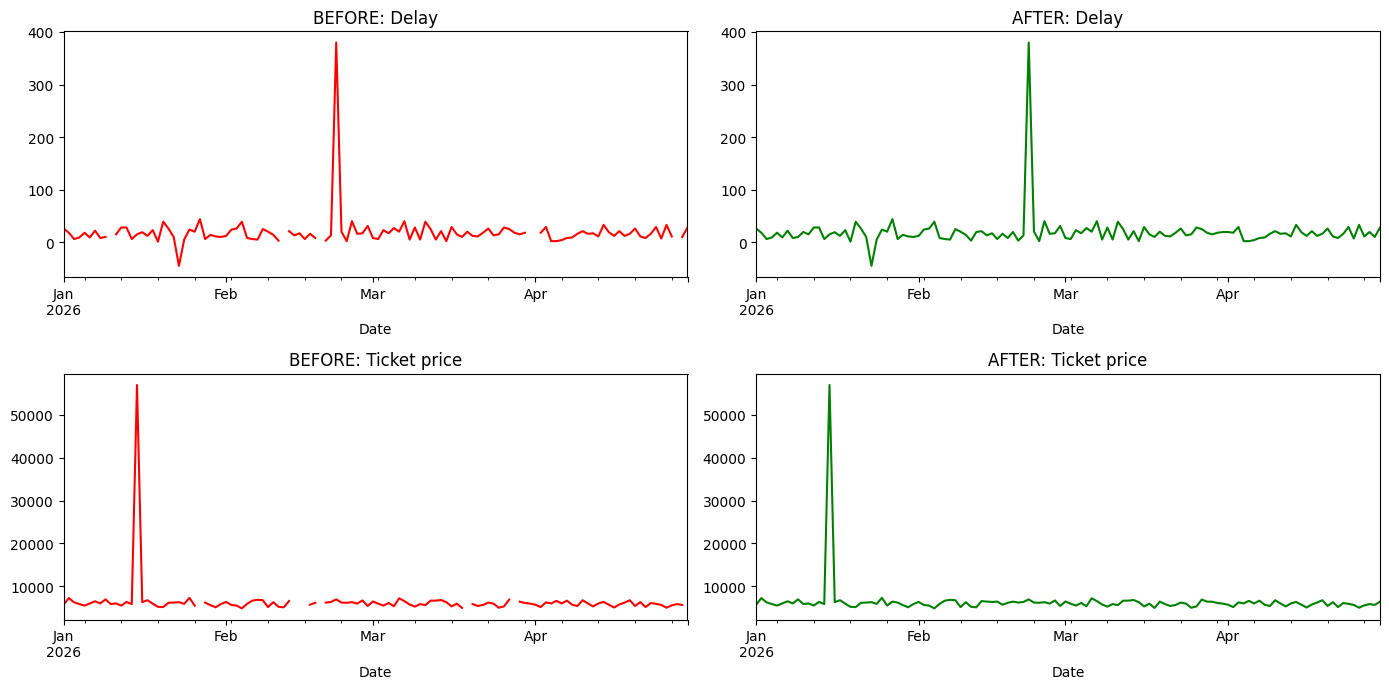

In [ ]:
#BEFORE vs AFTER time series
# Defining 'final' using the mean-imputed dataset
final = df_mean.copy()
ts_final = final.set_index("Date")

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

# Delay minutes: Before and After
ts_raw["Delay_Minutes"].plot(
    ax=axes[0, 0], color="red", title="BEFORE: Delay"
)

ts_final["Delay_Minutes"].plot(
    ax=axes[0, 1], color="green", title="AFTER: Delay"
)

# Ticket price: Before and After
ts_raw["Ticket_Price"].plot(
    ax=axes[1, 0], color="red", title="BEFORE: Ticket price"
)

ts_final["Ticket_Price"].plot(
    ax=axes[1, 1], color="green", title="AFTER: Ticket price"
)

plt.tight_layout()
plt.show()

ADVANCE DATA VISUALIZATION

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("Zepto_Orders_Data (1).xlsx", sheet_name="Orders")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 1200 | Columns: 14


,Order_ID,Order_Date,Time_Slot,State,City,Category,Customer_Type,Weather,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
0,ZP-0001,2026-07-01,Afternoon,Haryana,Gurugram,Snacks & Drinks,Pass Member,Clear,1.1,7,755,18,9,4.9
1,ZP-0002,2026-07-01,Evening,Tamil Nadu,Chennai,Household Items,Pass Member,Clear,1.9,5,835,0,8,5.0
2,ZP-0003,2026-07-01,Afternoon,NCT of Delhi,Delhi,Dairy & Bread,Pass Member,Clear,0.3,5,605,20,9,4.7
3,ZP-0004,2026-07-01,Late Night,Uttar Pradesh,Noida,Snacks & Drinks,Pass Member,Clear,3.7,5,420,20,19,4.5
4,ZP-0005,2026-07-01,Evening,Kerala,Kochi,Dairy & Bread,New User,Clear,0.5,10,670,39,8,5.0


DISCRIPTIVE STATSTICS


> Add blockquote



In [2]:
df.describe().round(1)

,Order_Date,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
count,1200,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
mean,2026-08-20 19:57:36,1.6,4.9,422.9,15.5,13.0,4.5
min,2026-07-01 00:00:00,0.3,1.0,50.0,0.0,4.0,2.8
25%,2026-07-31 00:00:00,0.8,3.0,230.0,8.0,9.0,4.2
50%,2026-08-23 00:00:00,1.3,5.0,350.0,14.0,12.0,4.6
75%,2026-09-12 00:00:00,2.2,6.0,560.0,22.0,16.0,4.9
max,2026-09-30 00:00:00,4.0,11.0,2230.0,46.0,31.0,5.0
std,NaN,1.0,2.0,270.3,9.9,4.9,0.4


In [5]:
#no. of orders  in a particular state
df["State"].value_counts()

,count
State,
Karnataka,223
NCT of Delhi,188
Maharashtra,182
Telangana,113
Haryana,107
Tamil Nadu,107
Uttar Pradesh,94
Gujarat,55
West Bengal,54


consistency of date

In [7]:
df["Week"]       = df["Order_Date"].dt.isocalendar().week.astype(int)
df["Weekday"]    = df["Order_Date"].dt.day_name()
df["Within_10_Min"] = df["Delivery_Time_Min"]<=10      #true if we kept the promise
#fixed order so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]
type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

,Order_Date,Week,Weekday,Within_10_Min
0,2026-07-01,27,Wednesday,True
1,2026-07-01,27,Wednesday,True
2,2026-07-01,27,Wednesday,True
3,2026-07-01,27,Wednesday,False
4,2026-07-01,27,Wednesday,True


In [8]:
import matplotlib.pyplot as plt

**MATPLOTLIB**
how long does a delivery takes and how many are inside the 10 mins promise?

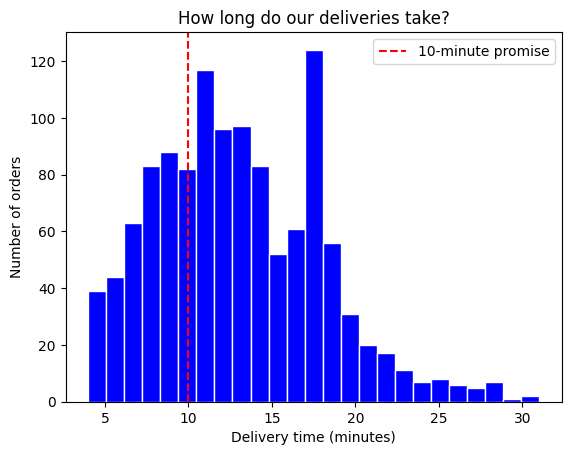

In [9]:
plt.hist(df["Delivery_Time_Min"], bins=25, color="blue", edgecolor="white")
plt.axvline(10, color="red", linestyle="--", label="10-minute promise")
plt.title("How long do our deliveries take?")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.legend()
plt.show()

business question: which product category brings the most sales

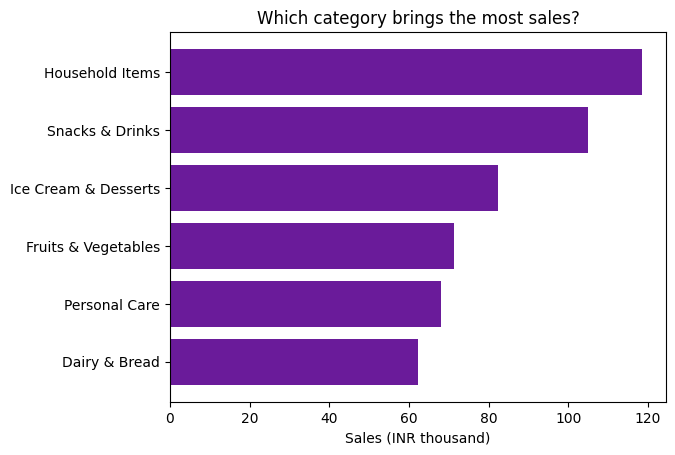

In [12]:
category_sales= df.groupby("Category")["Order_Value"].sum().sort_values()


plt.barh(category_sales.index,category_sales.values/1000,color="#6A1B9A")
plt.title("Which category brings the most sales?")


plt.xlabel("Sales (INR thousand)")


plt.show()

business problem Are orders growing week by week

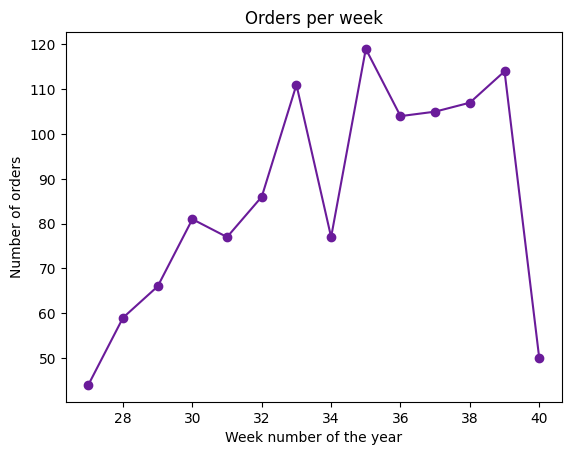

In [13]:
weekly_orders = df.groupby("Week")["Order_ID"].count()

plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6A1B9A")
plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

AREA PLOT
 business problem : which part of the day builds our weekly sales?

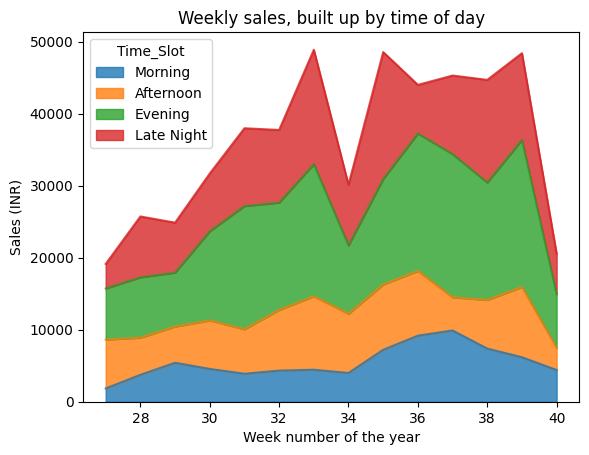

In [14]:
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")[slot_order]

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()

Business Question: does a longer distance mean a slower delivery and does a slow delivery means a lower rating?

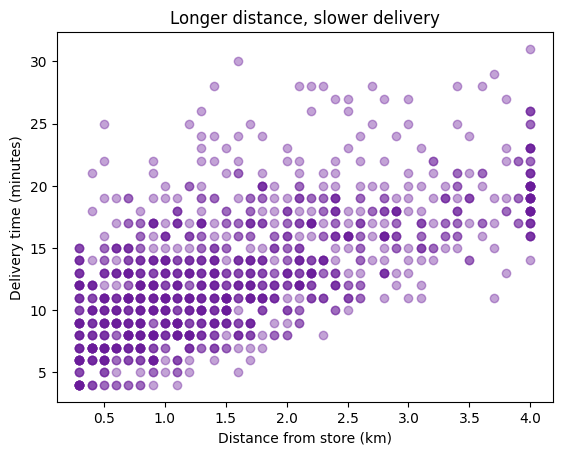

In [15]:
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

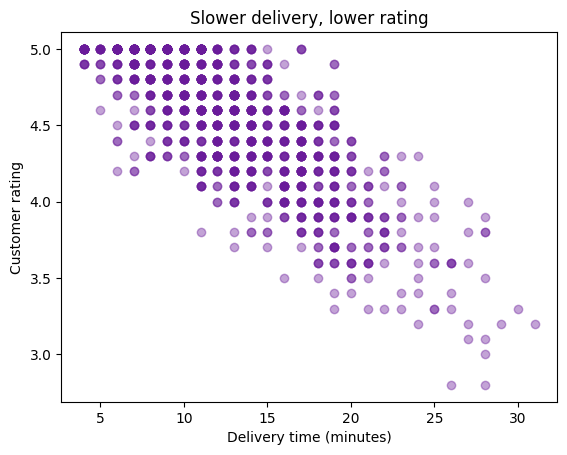

In [16]:
#delivery VS customer rating
plt.scatter(df["Delivery_Time_Min"], df["Customer_Rating"], alpha=0.4, color="#6A1B9A")
plt.title("Slower delivery, lower rating")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Customer rating")
plt.show()

Quiver Plots(using 3 variables but  show only 2 on screen)


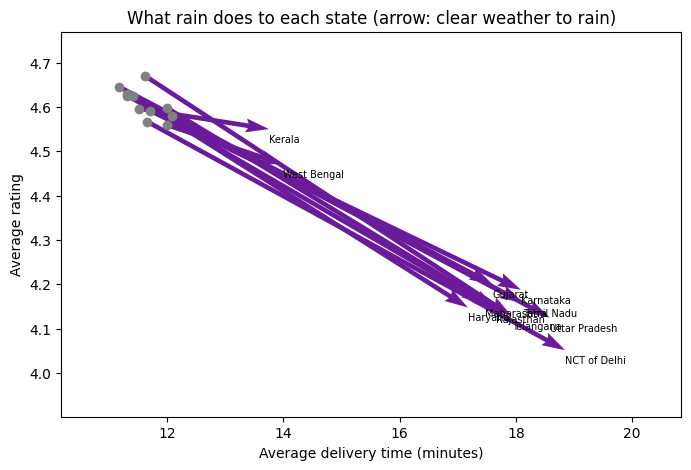

In [20]:
means = df.groupby(["State", "Weather"])[["Delivery_Time_Min", "Customer_Rating"]].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain  = means[means["Weather"] == "Rain"].set_index("State")

x  = clear["Delivery_Time_Min"]                          # arrow starts here (clear weather)
y  = clear["Customer_Rating"]
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]   # how far rain moves it
dy = rain["Customer_Rating"] - clear["Customer_Rating"]
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in clear.index:
    plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)   # label at the arrow tip

plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)
plt.title("What rain does to each state (arrow: clear weather to rain)")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Average rating")
plt.show()

CONTOUR PLOTS / 2D PLOTS
step-1 developing  matrix

In [21]:
#A tiny example first
distance = np.array([1, 2, 3])
basket   = np.array([5, 10])

D, B = np.meshgrid(distance, basket)

print(D)
print(B)

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


Step-2 divinding matrix

In [22]:
dist_values   = np.linspace(0.3, 4, 40)     # 40 distances, 0.3 to 4 km
basket_values = np.linspace(1, 12, 40)      # 40 basket sizes, 1 to 12 items

D, B = np.meshgrid(dist_values, basket_values)

print("Number of what-if cases:", D.size)

Number of what-if cases: 1600


Step-3 linear regression - prediction

In [23]:
# A simple formula from our data: delivery time from distance and basket size

from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(
    df[["Distance_KM", "Basket_Size"]],
    df["Delivery_Time_Min"]
)

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

Each extra km adds about 3.1 minutes
Each extra item adds about 0.31 minutes


Step-4 what if cases

In [25]:
#fill every what-if case with the expected delivery time
cases=pd.DataFrame({"Distance_KM": D.ravel(), "Basket_Size": B.ravel()})
T= formula.predict(cases).reshape(D.shape)

**Business Question:** how far can a store deliver,for a givden basket,and still keep the 10-minute promise

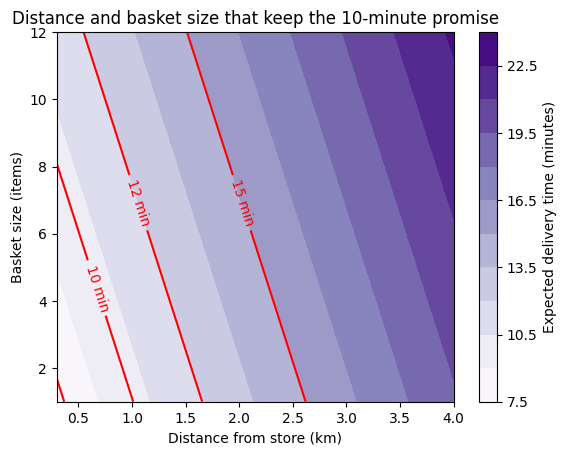

In [26]:
plt.contourf(D, B, T, levels=10, cmap="Purples")
plt.colorbar(label="Expected delivery time (minutes)")

lines = plt.contour(D, B, T, levels=[8, 10, 12, 15], colors="red")
plt.clabel(lines, fmt="%d min")

plt.title("Distance and basket size that keep the 10-minute promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")
plt.show()